# Final categories to build mask later / Choose ct_cat_id
# (Always using table_cells)

In [2]:
import pandas as pd
import json
import matplotlib.pyplot as plt
import os
import numpy as np
from matplotlib.ticker import FuncFormatter

In [3]:
def plot_cell_type_stacked_by_tissue(annots, col_label="final_label"):

    # Aggregate
    grouped = (
        annots.groupby([col_label, "tissue"], as_index=False)["cell_count"]
        .sum()
    )

    # Pivot to final_label x tissue, fill missing combos with 0
    pivot = grouped.pivot(index=col_label, columns="tissue", values="cell_count").fillna(0)

    # Sort x categories (final_label) by total cell count (descending) for clarity
    label_totals = pivot.sum(axis=1).sort_values(ascending=False)
    pivot = pivot.loc[label_totals.index]

    # Also fix a consistent tissue (stack) order by overall abundance
    tissue_totals = pivot.sum(axis=0).sort_values(ascending=False)
    pivot = pivot[tissue_totals.index]

    # Percentage of cells per-label
    percent = pivot.div(pivot.sum(axis=1).replace(0, np.nan), axis=0) * 100

    # Colors: lock a color per tissue so both subplots match
    tissues = list(pivot.columns)
    cmap = plt.get_cmap("tab20", len(tissues))  # discrete palette
    colors = {t: cmap(i) for i, t in enumerate(tissues)}

    def plot_stacked(ax, data, yscale=None, ylabel="", show_legend=False):
        """Draw a stacked bar chart for a DataFrame with index as x and columns as stacks."""
        x = np.arange(len(data))
        bottom = np.zeros(len(data), dtype=float)

        # draw stacks in consistent tissue order
        for t in data.columns:
            vals = data[t].to_numpy(dtype=float)
            ax.bar(x, vals, bottom=bottom, label=t, color=colors[t], width=0.85)
            bottom += vals

        if yscale:
            ax.set_yscale(yscale)
        ax.set_ylabel(ylabel)
        ax.set_xticks(x)
        ax.set_xticklabels(data.index, rotation=45, ha="right")
        ax.grid(axis="y", which="both", alpha=0.3)
        if show_legend:
            ax.legend(title="Tissue", ncol=1, bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)

    # Figure
    fig, (ax_pct, ax_cnt) = plt.subplots(
        1, 2, figsize=(18, max(6, len(pivot) / 3)), sharex=True, constrained_layout=False
    )

    # Top: % of all cells (log y)
    plot_stacked(
        ax_pct,
        percent,
        yscale="log",
        ylabel="Percentage of all cells (log scale)",
        show_legend=False,
    )
    ax_pct.set_title("Final labels stacked by tissue — percentage of all cells (log scale)")
    # Pretty % ticks on a log axis
    ax_pct.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g}%"))

    # Bottom: raw counts
    plot_stacked(
        ax_cnt,
        pivot,
        yscale=None,
        ylabel="Cell count",
        show_legend=True,
    )
    ax_cnt.set_title("Final labels stacked by tissue — raw counts")

    # Leave room on the right for legend
    plt.tight_layout(rect=[0, 0, 0.85, 1])
    plt.show()

In [4]:
annots = pd.read_csv('/path/to/ALHENA-paper/data/annots/labels_table_cells.csv')
annots = annots.rename(columns={'sample_id': 'slide_id'})
annots

,slide_id,tissue,label1,label2,label3,cell_count,final_label,combined_labels
0,kidney_s2,kidney,B,B,normal_cell,26814,B_Plasma,B_B_normal_cell
1,kidney_s2,kidney,Endothelial,Angiogenic_endothelial_cells,normal_cell,34368,Blood_vessel,Endothelial_Angiogenic_endothelial_cells_norma...
2,kidney_s2,kidney,Endothelial,Endothelial,normal_cell,15624,Blood_vessel,Endothelial_Endothelial_normal_cell
3,kidney_s2,kidney,Epithelial,Epithelial_tumor_cells,cancer_cell,57049,Epithelial,Epithelial_Epithelial_tumor_cells_cancer_cell
4,kidney_s2,kidney,Fibroblast,CAF,normal_cell,62335,Fibroblast_Myofibroblast,Fibroblast_CAF_normal_cell
...,...,...,...,...,...,...,...,...
312,tonsil_s1,tonsil,Plasma,Plasma,normal_cell,86599,B_Plasma,Plasma_Plasma_normal_cell
313,tonsil_s1,tonsil,Smooth_muscle,Smooth_muscle,normal_cell,3891,Blood_vessel,Smooth_muscle_Smooth_muscle_normal_cell
314,tonsil_s1,tonsil,T,T,normal_cell,118965,T_NK,T_T_normal_cell
315,tonsil_s1,tonsil,T,T_CD8,normal_cell,72900,T_NK,T_T_CD8_normal_cell


## ct_1

In [5]:
ct_cat_id = "ct_1"

In [7]:
kept_slide_ids = annots['slide_id'].unique()

# Remove "brain_s0", "bone_marrow_s0", "bone_marrow_s1", "bone_s0" and order the list of slide_ids
kept_slide_ids = [x for x in kept_slide_ids if x not in ["brain_s0", "bone_marrow_s0", "bone_marrow_s1", "bone_s0"]]
kept_slide_ids = sorted(kept_slide_ids)
print("Slide_ids:", kept_slide_ids)
print("Number:", len(kept_slide_ids))
print("Tissues:", annots[annots['slide_id'].isin(kept_slide_ids)]['tissue'].unique())

Slide_ids: ['breast_s0', 'breast_s1', 'breast_s3', 'breast_s6', 'cervix_s0', 'colon_s1', 'colon_s2', 'heart_s0', 'kidney_s0', 'kidney_s1', 'kidney_s2', 'liver_s0', 'liver_s1', 'lung_s1', 'lung_s3', 'lymph_node_s0', 'ovary_s0', 'ovary_s1', 'pancreatic_s0', 'pancreatic_s1', 'pancreatic_s2', 'prostate_s0', 'skin_s1', 'skin_s2', 'skin_s3', 'skin_s4', 'tonsil_s0', 'tonsil_s1']
Number: 28
Tissues: ['kidney' 'breast' 'cervix' 'colon' 'heart' 'liver' 'lung' 'lymph_node'
 'ovary' 'pancreatic' 'prostate' 'skin' 'tonsil']


In [8]:
annots.loc[annots['slide_id'].isin(kept_slide_ids), 'final_label'].unique()

array(['B_Plasma', 'Blood_vessel', 'Epithelial',
       'Fibroblast_Myofibroblast', 'Myeloid', 'T_NK', 'Unknown',
       'Specialized', 'Stem_like', 'Melanocyte'], dtype=object)

In [9]:
# Keep only selected slide_ids
annots_filtered = annots[annots['slide_id'].isin(kept_slide_ids)]

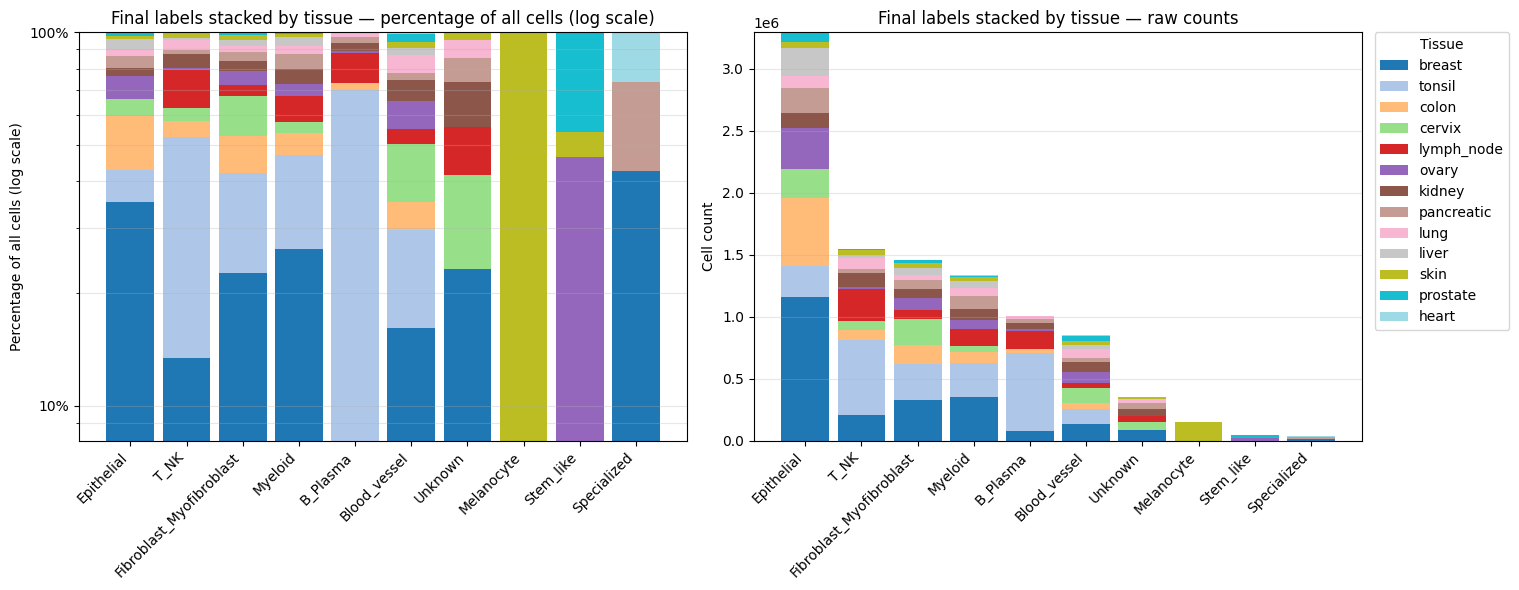

In [10]:
plot_cell_type_stacked_by_tissue(annots_filtered, col_label='final_label')

In [11]:
label2cat = {"T_NK" : "T_NK",
             "B_Plasma" : "B_Plasma",
             "Myeloid" : "Myeloid",
             "Blood_vessel" : "Blood_vessel",
             "Fibroblast_Myofibroblast" : "Fibroblast_Myofibroblast",
             "Epithelial" : "Epithelial",
             "Specialized" : "Specialized",
             "Melanocyte" : "Melanocyte",
             "Stem_like" : "Unknown",
             "Unknown" : "Unknown",
             "Less10" : "Unknown"
           }


cat2idx = {"T_NK" : 0,
          "B_Plasma" : 1,
          "Myeloid" : 2,
          "Blood_vessel" : 3,
          "Fibroblast_Myofibroblast" : 4,
          "Epithelial" : 5,
          "Specialized" : 6,
          "Melanocyte" : 7,
          "Unknown" : 8
          }


cat2color = {"T_NK" : [255, 15, 15],                    # Red
          "B_Plasma" : [255, 143, 15],                  # Orange
          "Myeloid" : [255, 211, 15],                   # Yellow
          "Blood_vessel" : [70, 128, 0],                # Dark Green
          "Fibroblast_Myofibroblast" : [156, 255, 36],  # Light Green
          "Epithelial" : [57, 208, 133],                # Blue Green
          "Specialized" : [69, 237, 255],               # Turquoise
          "Melanocyte" : [22, 169, 223],                # Blue
          "Unknown" : [143, 143, 143]                   # Grey
          }

In [12]:
os.makedirs(f"/path/to/ALHENA-paper/data/annots/annot_dicts_{ct_cat_id}/", exist_ok=True)

# Save dict label2cat in json file
with open(f"/path/to/ALHENA-paper/data/annots/annot_dicts_{ct_cat_id}/label2cat.json", "w") as f:
    json.dump(label2cat, f)

# Save dict cat2idx in json file
with open(f"/path/to/ALHENA-paper/data/annots/annot_dicts_{ct_cat_id}/cat2idx.json", "w") as f:
    json.dump(cat2idx, f)

# Save dict cat2color in json file
with open(f"/path/to/ALHENA-paper/data/annots/annot_dicts_{ct_cat_id}/cat2color.json", "w") as f:
    json.dump(cat2color, f)

/var/folders/ff/llzyqd_s78v1k8vywvjxp5_r0000gn/T/ipykernel_65639/749429200.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  annots_filtered[f'final_label_training_{ct_cat_id}'] = annots_filtered['final_label'].map(label2cat)


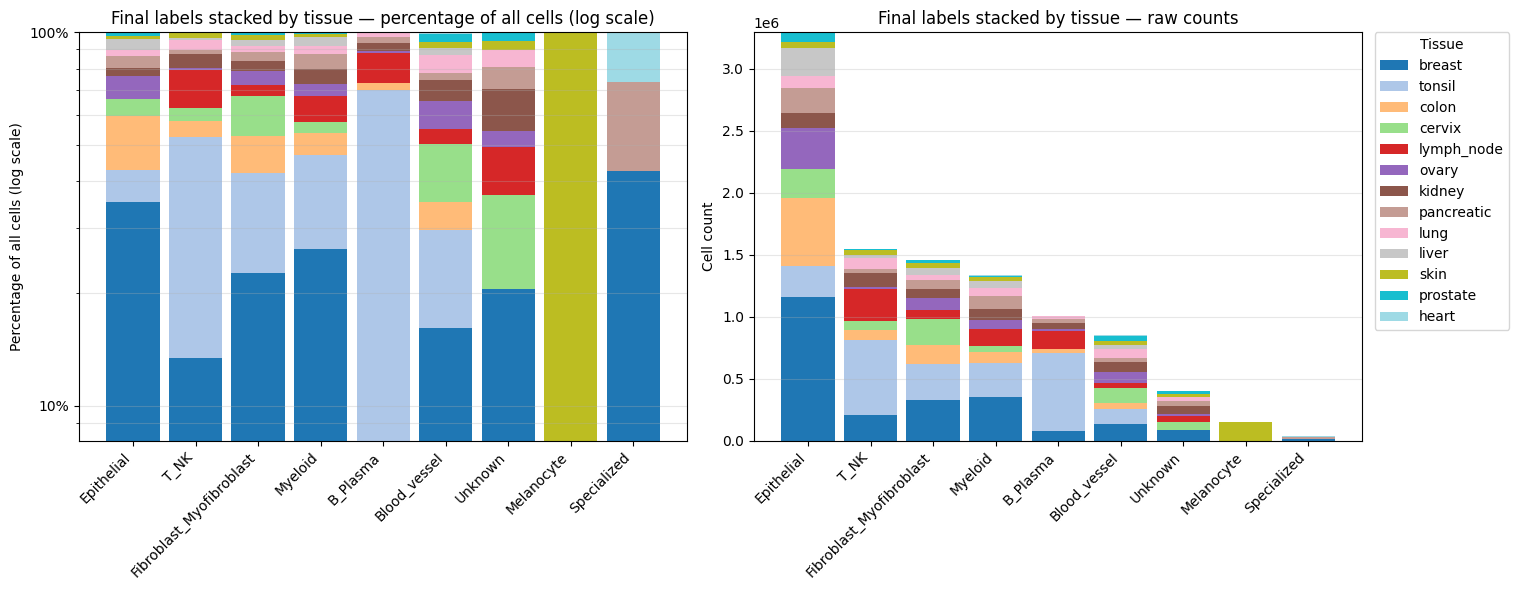

In [13]:
# Cell count per cell type and tissue

annots_filtered[f'final_label_training_{ct_cat_id}'] = annots_filtered['final_label'].map(label2cat)
plot_cell_type_stacked_by_tissue(annots_filtered, col_label=f'final_label_training_{ct_cat_id}')